# Zero-shot gene set analysis using Multicellular Transformer

Before starting, make sure that you have the repo installed. The repo can be found here - https://code.roche.com/braid-mltd/2024_mltd_summer_interns/maciek/cell-cell-interactions . 

In [ ]:
# the repo can be installed with the following command
!pip install git+https://code.roche.com/braid-mltd/2024_mltd_summer_interns/maciek/cell-cell-interactions.git

### Import the dependencies

In [1]:
import numpy as np
import gseapy as gp
import torch
import json
import pandas as pd

from lightning import seed_everything
from cell_cell_interactions.tl.grn import GeneEmbedding
from cell_cell_interactions.pl.grn import plot_gene_set

seed_everything(32)

Seed set to 32


32

## Load the pretrained Multicellular Transformer weights

and extract the classifier weights representing gene embeddings.

In [ ]:
ckpt_path = "/Users/maciejwiatrak/Downloads/mct_checkpoint_12k.ckpt"

mct_embeddings = torch.load(
    ckpt_path, map_location="cpu"
)['state_dict']['model.gene_id_classifier.decoder.weight']  # extract gene embeddings from the classifier head weights

# load ENSEMBL ID to idx map
with open("data/gene_symbol2idx.json", "r") as f:
    gene_symbol2idx = json.load(f)

### Subset to highly variable genes from the tumor microenvironment atlas

Running the leiden clustering on all genes is computationally expensive and we are also often not interested in all genes, so we subset to 8k highly variable genes.
Additionally, we enrich the highly variable genes with receptor & ligand genes as these are of particular interest.

We use a precomputed list of highly variable genes for usability. The highly variable genes were extracted from -https://cellxgene.cziscience.com/collections/3f7c572c-cd73-4b51-a313-207c7f20f188 .

In [4]:
# set nr of HVG to 8000
top_k = 5000
# extract HVGs
hvg_genes = pd.read_csv("data/tumor_microenvironment_hvg_genes.csv")['gene_name'][:top_k].tolist()
# extract receptor & ligand genes, the genes were extracted from LIANA consensus receptor ligand gene set
receptor_ligand_genes = pd.read_csv('data/receptors_and_ligands.csv')['gene_name'].tolist()
# combine HVGs with receptor & ligand genes
all_genes = list(set(hvg_genes + receptor_ligand_genes))
# subset to genes with pretrained embedding
all_genes = [gene for gene in all_genes if gene in gene_symbol2idx]
print("Total nr of genes:", len(all_genes))

# use only selected subset of genes for clustering
embed = GeneEmbedding({gene: mct_embeddings[gene_symbol2idx[gene]].numpy() for gene in all_genes})

Total nr of genes: 6145


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6145/6145 [00:00<00:00, 3537468.86it/s]


## Perform Leiden clustering

In [5]:
# Perform Leiden clustering with desired resolution
# lower resolutions are gonna give larger gene sets
# higher resolutions are gonna give smaller, more specific gene sets
gdata = embed.get_adata(resolution=40)
# Retrieve the gene clusters
gene_sets = embed.get_metagenes(gdata)
# filter gene sets with nr of genes lower than 4
gene_sets = {gid: gs for gid, gs in gene_sets.items() if len(gs) >= 4}
gene_set_sizes = [len(gs) for gs in gene_sets.values()]
print(f"Nr of gene sets: {len(gene_sets)}, average gene set size: {np.mean(gene_set_sizes)}, " 
      f"std gene set size: {np.std(gene_set_sizes)}")

/Users/wiatrakm/cell-cell-interactions/ccc/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.
/Users/wiatrakm/cell-cell-interactions/cell_cell_interactions/tl/grn.py:44: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(gdata, resolution=resolution)


Nr of gene sets: 556, average gene set size: 10.949640287769784, std gene set size: 5.525706753204125


## Analyse gene set

Let's select a gene set which has a gene of interest and analyse other genes present in the gene set.

In [6]:
# select a gene set with CD14 gene
cd14_gene_set = [gs for gs_id, gs in gene_sets.items() if 'CD14' in gs][0]
cd14_gene_set

['LPCAT2', 'SIRPA', 'TLR4', 'EPB41L3', 'ACER3', 'STAB1', 'CD14']

  0%|                                                                                                                                                                                                        | 0/7 [00:00<?, ?it/s]/Users/wiatrakm/cell-cell-interactions/cell_cell_interactions/pl/grn.py:13: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_gs = pd.concat([df_gs, df])
100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 7/7 [00:00<00:00, 127.66it/s]


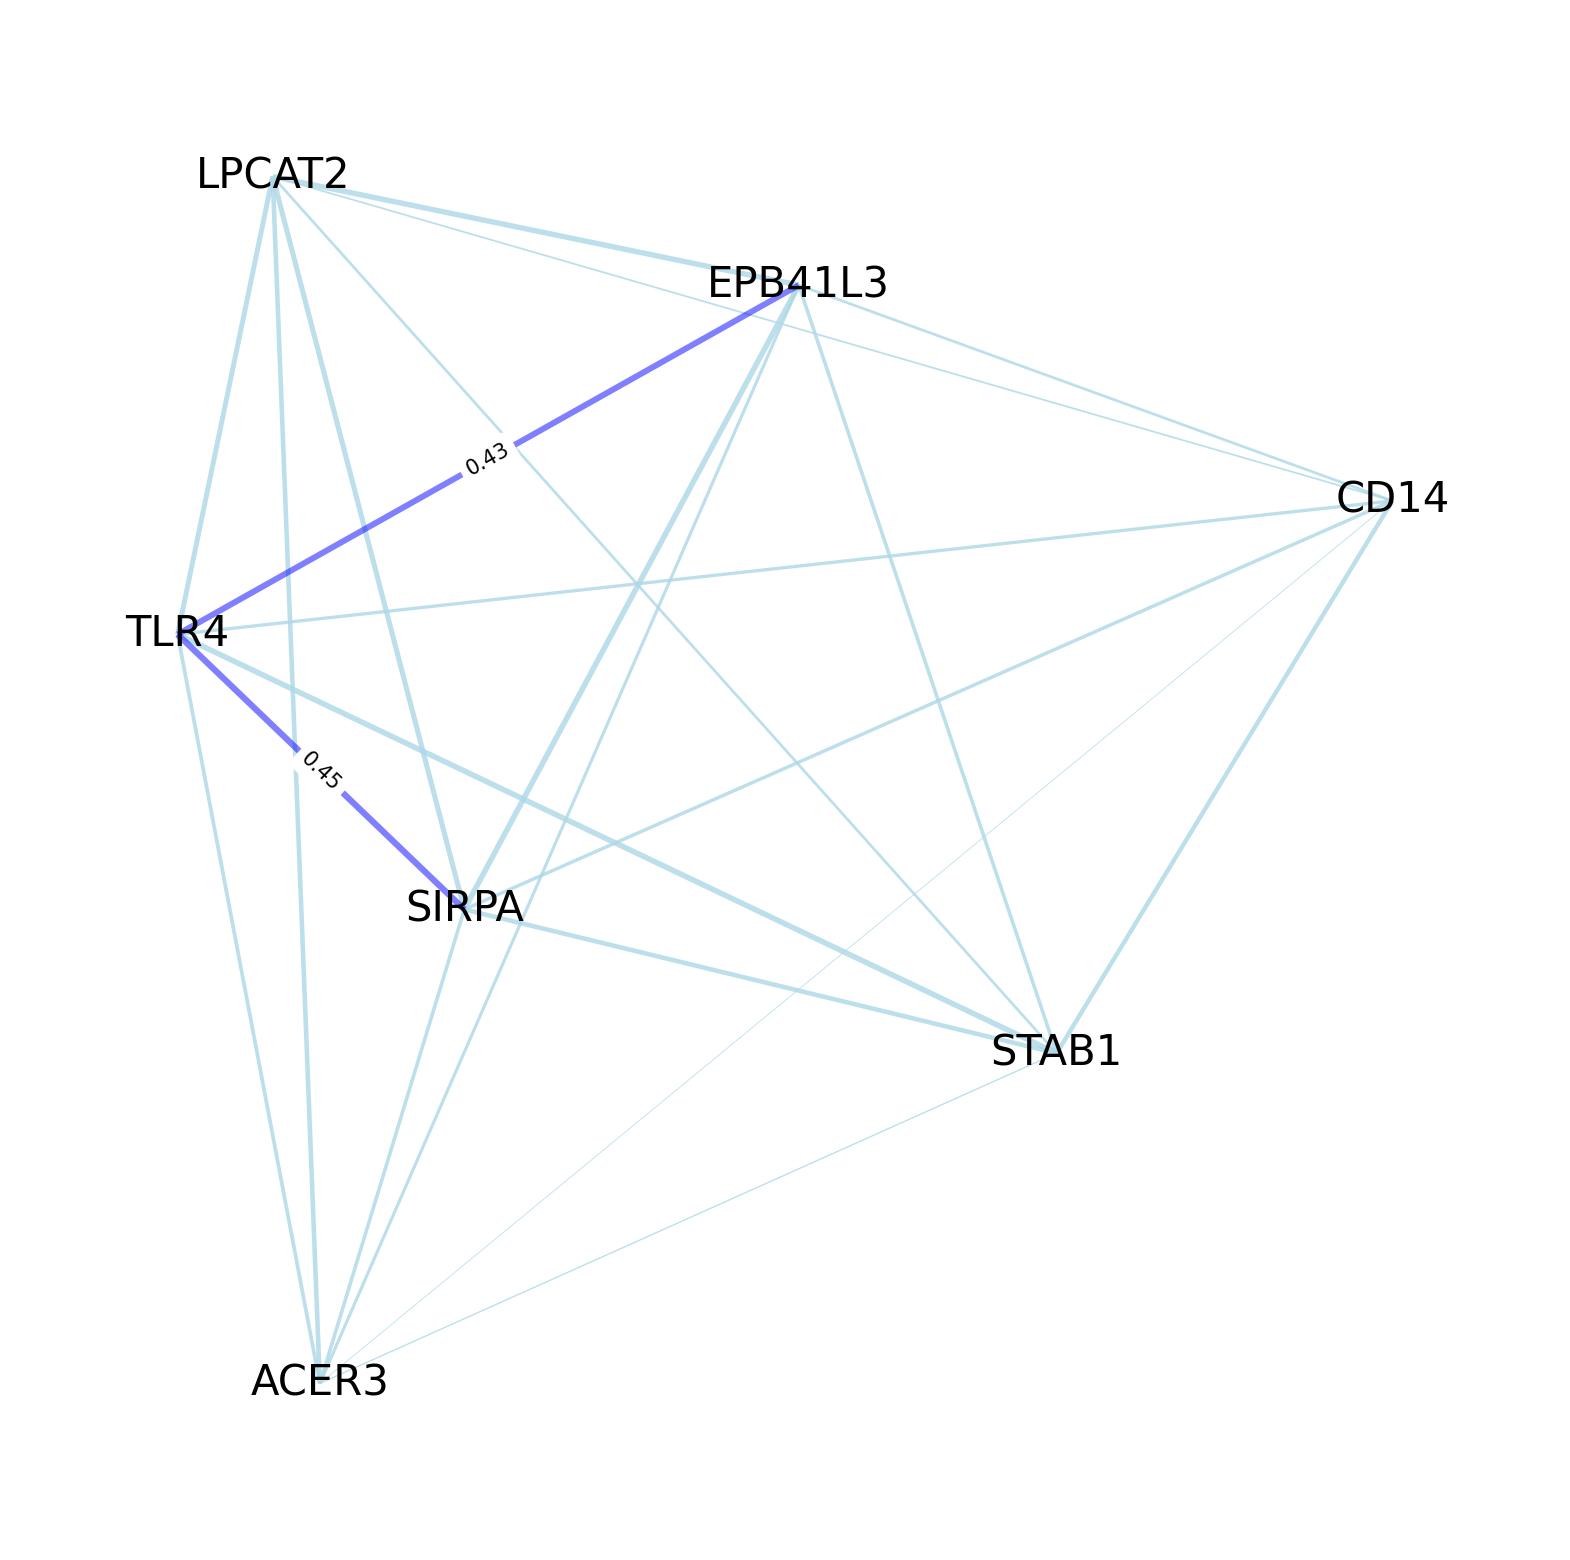

In [7]:
# plot the gene set highlighting the strongest connections
plot_gene_set(cd14_gene_set, embed, thresh=0.4, seed=2)

## Perform gene set enrichment analysis

Extract pathways enriched in the gene set.

In [8]:
# Code below has been taken from https://github.com/bowang-lab/scGPT/blob/main/tutorials/Tutorial_GRN.ipynb
# Meta info about the number of terms (tests) in the databases
df_database = pd.DataFrame(
    data=[
        ['GO_Biological_Process_2021', 6036],
        ['GO_Molecular_Function_2021', 1274],
        ['Reactome_2022', 1818]],
    columns = ['dataset', 'term']
)

# Select desired database for query; here use Reactome as an example
databases = ['GO_Biological_Process_2021']
m = df_database[df_database['dataset'].isin(databases)]['term'].sum()
# p-value correction for total number of tests done
p_thresh = 0.05/m

# get enriched pathways
enr_Reactome = gp.enrichr(
    gene_list=cd14_gene_set,
    gene_sets=databases,
    organism='Human', 
    outdir='test/enr_Reactome',
    cutoff=0.5
)
pathways_df = enr_Reactome.results
pathways_df = pathways_df[pathways_df['P-value'] < p_thresh]

In [9]:
pathways_df

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
0,GO_Biological_Process_2021,negative regulation of MyD88-independent toll-...,2/7,0.000002,0.000212,0,0,1599.040000,20828.531415,CD14;TLR4
1,GO_Biological_Process_2021,regulation of interferon-gamma production (GO:...,3/86,0.000003,0.000212,0,0,179.909639,2309.985134,SIRPA;CD14;TLR4
2,GO_Biological_Process_2021,regulation of MyD88-independent toll-like rece...,2/8,0.000003,0.000212,0,0,1332.466667,16973.131805,CD14;TLR4
3,GO_Biological_Process_2021,cellular response to molecule of bacterial ori...,3/115,0.000006,0.000289,0,0,133.131696,1592.700642,SIRPA;CD14;TLR4
4,GO_Biological_Process_2021,cellular response to lipopolysaccharide (GO:00...,3/120,0.000007,0.000289,0,0,127.410256,1507.940715,SIRPA;CD14;TLR4
5,GO_Biological_Process_2021,regulation of tumor necrosis factor production...,3/124,0.000008,0.000289,0,0,123.173554,1445.654819,SIRPA;CD14;TLR4
